In [5]:
%pip install pandas httpx trafilatura pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from pathlib import Path

import pandas as pd


In [3]:
mediacloud = pd.DataFrame()
for root, dirs, files in os.walk("./"):
    for filename in files:
        if filename.endswith(".csv"):
            df = pd.read_csv(os.path.join(root, filename))
            mediacloud = pd.concat([mediacloud, df], ignore_index=True)

display(mediacloud.head())

,id,indexed_date,language,media_name,media_url,publish_date,title,url
0,746dae770b1791f88fc9356605a74c1604b4a8263d3294...,2026-08-04 14:18:02.867043+00:00,en,time.com,time.com,2022-07-20,Weather Forecasts Are Connecting Hot Days to C...,https://time.com/collections/ecopreneurs/61989...
1,63fd0eccdf35941ccf1351a3f03b9f12f6252f7b6a6565...,2026-06-30 21:30:41.199371+00:00,en,fortune.com,fortune.com,2022-06-07,"How Bloomberg used new language A.I. to ""tame ...",https://fortune.com/2022/06/07/bloomberg-nlp-a...
2,fa8ee97488cf217c55d0de695c392fbe3e4860254a2c2e...,2026-05-28 16:19:50.521067+00:00,en,stltoday.com,stltoday.com,2022-04-24,3 of the best apps for account management and ...,https://www.stltoday.com/life-entertainment/te...
3,a7bc3d52f4ea6b7b3708ad3da6d56294090709a7811b50...,2026-05-18 22:43:28.955625+00:00,en,cbsnews.com,cbsnews.com,2022-09-30,CBS News Baltimore Sports Live,https://www.cbsnews.com/newyork/video/live-bal...
4,65ec187024d367d03db24d6ee2591d25b4a5f35eed043d...,2026-05-12 15:42:46.932987+00:00,en,reuters.com,reuters.com,2022-09-19,Iraq's political stalemate pushes climate acti...,https://www.reuters.com/world/iraqs-political-...


In [4]:
# publish_date per month (ex. 2022-07-20 -> 2022-07)
mediacloud["publish_month"] = pd.to_datetime(mediacloud["publish_date"]).dt.to_period(
    "M"
)

# get month counts
media_month_counts = (
    mediacloud.groupby(["publish_month", "media_name"])
    .aggregate({"publish_date": "count"})
    .rename(columns={"publish_date": "count"})
)

# display(media_month_counts.head())

# get month proportions
media_month_proportions = mediacloud.groupby(["publish_month", "media_name"]).aggregate(
    {"publish_date": "count"}
).rename(columns={"publish_date": "count"}) / mediacloud.groupby(
    ["publish_month"]
).aggregate({"publish_date": "count"}).rename(columns={"publish_date": "count"})
# display(media_month_proportions.head())

# check 2008-01 for proportion sum to 1
# display(media_month_proportions.loc["2008-01"].sum())


## Full-text scrape (~1.27M URLs)

**Possible?** Yes, as a multi-day batch job — not a notebook `for` loop.

**Banned?** Likely if you hammer one site. This set is concentrated (Reuters ~113k, Guardian ~66k, NYT ~59k). The scraper rate-limits **per host** and runs concurrency **across** hosts.

**Memory?** Do **not** keep all text in a DataFrame. Append to parquet shards; resume via SQLite. Expect roughly multi-GB to tens of GB on disk, and a large miss rate (paywalls, 404s, bot blocks, video pages). MediaCloud cannot ship full text for copyright reasons.

Run from this folder (or a terminal):
```bash
../.venv/bin/python scrape_articles.py --limit 50    # smoke test
../.venv/bin/python scrape_articles.py               # full run (resumable)
../.venv/bin/python scrape_articles.py --status
```

In [5]:
# Load scraped text shards produced by scrape_articles.py
from IPython.display import display

SCRAPED = Path("scraped")
shards = sorted(SCRAPED.glob("text_*.parquet")) if SCRAPED.exists() else []
if not shards:
    print("No shards yet. Run: ../.venv/bin/python scrape_articles.py --limit 50")
else:
    texts = pd.concat([pd.read_parquet(p) for p in shards], ignore_index=True)
    print(f"loaded {len(texts):,} articles from {len(shards)} shards")
    display(texts[["id", "media_name", "title", "text"]].head(3))
    # Join later if needed:
    # mediacloud_with_text = mediacloud.merge(texts[["id", "text"]], on="id", how="left")

loaded 554,038 articles from 559 shards


,id,media_name,title,text
0,0964524a4526dd5f4c3bfcf9bfce81175249f1261d9641...,nytimes.com,Behind the Cover Story: Nathaniel Rich on the ...,"Nathaniel Rich, a contributing writer for the ..."
1,0d110e1f06a6eb903c164163d65bf2d3776dc49e68b400...,nytimes.com,Behind the Cover Story: Paul Tullis on Underst...,"Paul Tullis, a contributing writer for the mag..."
2,655c233f39fe00f6da0ce837afe0a734a634e37db03e2a...,nytimes.com,David Leonhardt on Economic Growth and E-Books...,"David Leonhardt, The Times’s Washington bureau..."


## BERT embeddings + clustering

Uses Sentence-BERT (`all-mpnet-base-v2`) on GPU to embed scraped articles, caches vectors by `id`, then UMAP (2D) + HDBSCAN for clusters.

In [11]:
%pip install sentence-transformers umap-learn hdbscan scikit-learn torch matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 760.7/760.7 kB 16.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 22.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 27.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 14.3 MB/s  0:00:00 16.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 21.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 24.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 21.1 MB/s  0:00:006.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 21.2 MB/s  0:00:06a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 28.9 MB/s  0:00:001.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 14.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 28.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 29.6 MB/s  0:00:00
   ━━━━━━━━━━━

In [6]:
import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import torch
import umap
from IPython.display import display
from sentence_transformers import SentenceTransformer

if torch.cuda.is_available():
    DEVICE = "cuda"
elif (
    getattr(torch.backends, "mps", None) is not None
    and torch.backends.mps.is_available()
):
    DEVICE = "mps"
else:
    raise RuntimeError(
        "No GPU available. Install a CUDA (or Apple MPS) build of torch and restart the kernel."
    )

print(f"embedding device: {DEVICE}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))

/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1107 15:12:56.389000 39533 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


embedding device: mps


In [7]:
# Load scraped articles for embedding
SCRAPED = Path("scraped")
EMB_DIR = Path("embeddings")
EMB_DIR.mkdir(exist_ok=True)
EMB_PATH = EMB_DIR / "article_embeddings.parquet"

shards = sorted(SCRAPED.glob("text_*.parquet"))
if not shards:
    raise FileNotFoundError(
        "No scraped/text_*.parquet files — run scrape_articles.py first."
    )

articles = pd.concat([pd.read_parquet(p) for p in shards], ignore_index=True)
articles = articles.drop_duplicates(subset=["id"]).copy()
articles["title"] = articles["title"].fillna("").astype(str)
articles["text"] = articles["text"].fillna("").astype(str)
articles = articles[articles["text"].str.len() >= 100].reset_index(drop=True)
articles["embed_text"] = articles["title"] + "\n\n" + articles["text"]

print(f"articles ready to embed: {len(articles):,}")
articles[["id", "media_name", "title"]].head(3)

articles ready to embed: 553,569


,id,media_name,title
0,0964524a4526dd5f4c3bfcf9bfce81175249f1261d9641...,nytimes.com,Behind the Cover Story: Nathaniel Rich on the ...
1,0d110e1f06a6eb903c164163d65bf2d3776dc49e68b400...,nytimes.com,Behind the Cover Story: Paul Tullis on Underst...
2,655c233f39fe00f6da0ce837afe0a734a634e37db03e2a...,nytimes.com,David Leonhardt on Economic Growth and E-Books...


In [8]:
# Incremental Sentence-BERT embeddings (cached by article id)
MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"
BATCH_SIZE = 64  # lower if you hit GPU OOM

if EMB_PATH.exists():
    emb_cache = pd.read_parquet(EMB_PATH)
    cached_ids = set(emb_cache["id"])
    print(f"cache hit: {len(cached_ids):,} embeddings")
else:
    emb_cache = pd.DataFrame(columns=["id", "embedding"])
    cached_ids = set()

to_embed = articles[~articles["id"].isin(cached_ids)].copy()
print(f"new articles to embed: {len(to_embed):,}")

if len(to_embed):
    model = SentenceTransformer(MODEL_NAME, device=DEVICE)
    vectors = model.encode(
        to_embed["embed_text"].tolist(),
        batch_size=BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    new_rows = pd.DataFrame(
        {
            "id": to_embed["id"].tolist(),
            # store as plain lists so parquet round-trips cleanly
            "embedding": [v.astype(np.float32).tolist() for v in vectors],
        }
    )
    emb_cache = pd.concat([emb_cache, new_rows], ignore_index=True)
    emb_cache = emb_cache.drop_duplicates(subset=["id"], keep="last")
    emb_cache.to_parquet(EMB_PATH, index=False)
    print(f"wrote {EMB_PATH} ({len(emb_cache):,} rows)")
else:
    print("nothing new to embed")

# Align embeddings to current articles frame
emb_cache = emb_cache[emb_cache["id"].isin(articles["id"])].copy()
articles = articles.merge(emb_cache, on="id", how="inner")
X = np.asarray(articles["embedding"].tolist(), dtype=np.float32)
print(f"embedding matrix: {X.shape}")

cache hit: 17,942 embeddings
new articles to embed: 487,627


Batches:   1%|          | 95/7620 [03:33<4:41:31,  2.24s/it]


KeyboardInterrupt: 

In [ ]:
# UMAP 2D + HDBSCAN clusters
reducer = umap.UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
coords = reducer.fit_transform(X)
articles["umap_x"] = coords[:, 0]
articles["umap_y"] = coords[:, 1]

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=25,
    min_samples=5,
    metric="euclidean",
    cluster_selection_method="eom",
)
articles["cluster"] = clusterer.fit_predict(coords)

n_clusters = int(articles.loc[articles["cluster"] >= 0, "cluster"].nunique())
n_noise = int((articles["cluster"] == -1).sum())
print(
    f"clusters: {n_clusters:,}  |  noise: {n_noise:,} ({100 * n_noise / len(articles):.1f}%)"
)

cluster_sizes = (
    articles[articles["cluster"] >= 0]
    .groupby("cluster")
    .size()
    .sort_values(ascending=False)
)
display(cluster_sizes.head(15).to_frame("n_articles"))

top_media = (
    articles[articles["cluster"] >= 0]
    .groupby(["cluster", "media_name"])
    .size()
    .rename("n")
    .reset_index()
    .sort_values(["cluster", "n"], ascending=[True, False])
    .groupby("cluster")
    .head(3)
)
display(top_media.head(30))

/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


clusters: 173  |  noise: 5,084 (28.3%)


,n_articles
cluster,
43,548
56,437
159,401
33,347
96,267
115,218
127,195
92,194
76,186


,cluster,media_name,n
1,0,espn.com,23
3,0,nbcsports.com,17
2,0,foxsports.com,5
7,1,nbcnews.com,41
8,1,radaronline.com,1
9,2,nytimes.com,34
10,3,businessinsider.com,62
11,3,thenation.com,1
13,4,chron.com,154
21,4,sun-sentinel.com,9


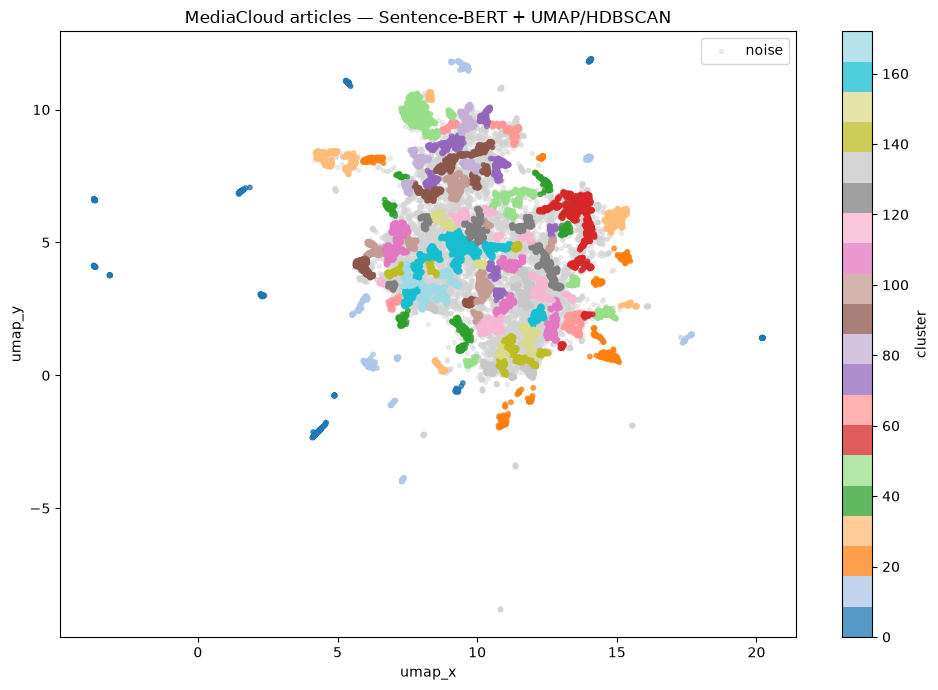


=== cluster 43 (n=548) ===


,media_name,title
53,cnn.com,The beef with beef
170,eater.com,What Does ‘Plant-Based’ Actually Mean?
245,eater.com,A Fast-Casual Israeli Food Favorite Is Coming ...
259,nytimes.com,An Almost-Meatless Diet
267,nytimes.com,Can Health Information Make You Fatter?



=== cluster 56 (n=437) ===


,media_name,title
110,thewrap.com,Sundance Institute Invites 10 Fellows to Produ...
115,refinery29.com,Drunk Movie Scenes Tequila Shots Cinco De Mayo...
138,uproxx.com,Here’s Everything New On Hulu For November 2020
141,variety.com,"‘Ostrov – Lost Island,’ ‘Zo Reken’ Win Hot Doc..."
149,polygon.com,Cruella can be Disney and still be punk as hell



=== cluster 159 (n=401) ===


,media_name,title
223,truth-out.org,Is It Time To Charge People With Ecocide?
249,saturdayeveningpost.com,Why Do We Ignore the Dire Warnings of Scientis...
257,foxnews.com,"The Left's ""Climate Change"""
316,nytimes.com,Failing to Deliver a Jolt on Global Warming
319,breitbart.com,Forget Climategate: this 'global warming' scan...


... (6 outputs left out)


=== cluster 127 (n=195) ===


,media_name,title
45,livescience.com,'The US has returned to the moon': Private com...
102,opednews.com,Kirkpatrick Sale Intvw Transcript: on Evolutio...
189,cnn.com,CNN Academy Abu Dhabi opens with climate maste...
203,tnr.com,The Usefulness of Cranks: Is Environmentalism ...
262,nhgazette.com,Is This the Beginning or the End?



=== cluster 92 (n=194) ===


,media_name,title
87,qz.com,EV startup Canoo spent more on its CEO's priva...
157,wired.com,"Tesla Shifts Gears, Again, and Some Fans Are L..."
255,opensecrets.org,Electric vehicle companies increased their lob...
256,jsonline.com,Johnson Controls to spin off auto business int...
378,nytimes.com,"Electric Cars for All! (No, Really This Time)"


In [ ]:
# Scatter plot + sample titles per cluster
fig, ax = plt.subplots(figsize=(10, 7))
noise = articles["cluster"] == -1
ax.scatter(
    articles.loc[noise, "umap_x"],
    articles.loc[noise, "umap_y"],
    c="lightgray",
    s=8,
    alpha=0.4,
    label="noise",
)
labeled = articles[~noise]
if len(labeled):
    sc = ax.scatter(
        labeled["umap_x"],
        labeled["umap_y"],
        c=labeled["cluster"],
        cmap="tab20",
        s=10,
        alpha=0.75,
    )
    fig.colorbar(sc, ax=ax, label="cluster")
ax.set_title("MediaCloud articles — Sentence-BERT + UMAP/HDBSCAN")
ax.set_xlabel("umap_x")
ax.set_ylabel("umap_y")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# A few titles from the largest clusters
for cluster_id in cluster_sizes.head(8).index:
    sample = articles[articles["cluster"] == cluster_id][["media_name", "title"]].head(
        5
    )
    print(f"\n=== cluster {cluster_id} (n={cluster_sizes.loc[cluster_id]}) ===")
    display(sample)

In [ ]:
# Optional: persist clustered metadata (without raw embedding vectors)
clustered_path = EMB_DIR / "articles_clustered.parquet"
articles.drop(columns=["embed_text", "embedding"]).to_parquet(
    clustered_path, index=False
)
print(f"wrote {clustered_path} ({len(articles):,} rows)")